# Which weights make the model pick one algorithm (BASE-W, iteration 10)

When Qwen3-8B writes a program, it commits to an algorithm at a single **fork token**. Asked to count the connected components of a graph, the instruct model opens `def solve(n, edges):` with a helper named `def find` (union-find) almost every time. The base model, Qwen3-8B-Base, is as likely to write `def dfs` or `def bfs`. This artifact asks **which weights** post-training changed to create that default:

* **W1, readout rows:** the fork-class rows of the unembedding matrix (`lm_head`) and the final-norm gain.
* **W2, late-MLP weights:** MLP layers 26-35 swapped to the base model in place.
* **W3:** the W1 row test repeated on Gemma-3-4b (descriptive).

**Units.** The prompts and fork tokens come from iteration 9.

| unit | task | default class D (instruct) | alternative class A |
|---|---|---|---|
| **T10** (primary) | connected components, 20 prompts | `' find'` (union-find) | `' dfs'`, `' bfs'` |
| **B3** (beside) | minimum spanning tree, 20 prompts | 8 Kruskal-class tokens | 8 Prim-class tokens |

**Margin and share.** The fork's **class margin** is `m = lse(z[D]) - lse(z[A])`, which equals log P(D) - log P(A). An intervention ("arm") is scored by the **share of the instruct-minus-base gap it closes**: `share = sum_p (m_I - m_arm) / sum_p (m_I - m_B)`. This is a ratio of sums over prompts, with a 95% prompt bootstrap. A share of 0 means no effect; a share of 1 means the margin became fully base-like.

### What this notebook runs
`method.py` is a stage orchestrator: it launches about 40 scripts that load the 8B models on a 24 GB GPU (about 1 GPU-hour), which cannot run on a Colab CPU in 10 minutes. The core of the method does not need a GPU, though. **The class margin depends only on the final-normed residual at the fork and on the fork-class unembedding rows**, so every W1 arm and every null is exact arithmetic on the cached fork states. This notebook:

1. shows the orchestrator (`method.py`) and its stage plan;
2. re-runs the **W1 teacher-forced test** (`src/w1_tf.py`): readout arms, 3 x 50 matched-norm null edits, bootstrap CIs and the committed verdict rule;
3. re-runs the **delta-geometry** analysis (`src/analysis10.py`);
4. draws the figures from `src/figures10.py`, including the activation-space plots: the fork states on the readout plane (F5) and the PCA of the block-35 outputs (F6).

`mini_demo_data.json` holds:
* the cached fork states of 20 + 20 prompts (bf16, exact);
* the fork-class `lm_head` rows and the final-norm gains of both models, fetched at the pinned revisions;
* the residual's top-64 PCA basis;
* the committed DELTA_SWAP draws for T10;
* the artifact's reported numbers, for a side-by-side check.

The generation experiments (W1-GEN), W2 and W3 need model forwards on a GPU. Their reported results are summarized before the last cell.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru: NOT pre-installed on Colab, always install (the original scripts log with loguru)
_pip('loguru==0.7.3')

# numpy, matplotlib, torch: pre-installed on Colab; install locally only, at Colab's versions (torch as the CPU build)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'matplotlib==3.10.0')
    _pip('torch==2.9.0+cpu', '--index-url', 'https://download.pytorch.org/whl/cpu',
         '--extra-index-url', 'https://pypi.org/simple')

In [2]:
from __future__ import annotations

# --- method.py (the stage orchestrator): imports as in the original
import argparse
import json
import os
import subprocess
import sys
import time
from pathlib import Path

# --- src/w1_tf.py, src/analysis10.py, src/figures10.py and iteration 9's stats9.py: imports as in the originals
#     (safetensors is not needed: the fork-class rows come from the data file instead of the 16 GB checkpoints)
import types
from typing import Any, Sequence

import numpy as np
import torch
from loguru import logger

# --- notebook additions: array decoding and inline figures
import base64
import matplotlib.pyplot as plt
from IPython.display import display

torch.set_num_threads(min(12, os.cpu_count() or 1))     # original: torch.set_num_threads(12)
print("torch", torch.__version__, "| numpy", np.__version__)

torch 2.9.0+cpu | numpy 2.0.2


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-10/experiment-56/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")


def arr(spec: dict) -> torch.Tensor:
    """Decode one array of mini_demo_data.json ({dtype, shape, b64}: base64 of little-endian raw bytes).
    bfloat16 arrays are stored as their uint16 bit patterns; (u16 << 16) viewed as float32 is the exact value."""
    raw = base64.b64decode(spec["b64"])
    if spec["dtype"] == "bfloat16":
        f32 = (np.frombuffer(raw, dtype="<u2").astype(np.uint32) << 16).view(np.float32)
        return torch.from_numpy(f32.reshape(spec["shape"]).copy()).to(torch.bfloat16)
    return torch.from_numpy(np.frombuffer(raw, dtype="<f4").reshape(spec["shape"]).copy())

In [4]:
data = load_data()
print({u: f"{len(U['examples'])} prompts" for u, U in data["units"].items()}, "|",
      {k: f"{v['id']}@{v['revision'][:8]}" for k, v in data["models"].items()})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found


{'T10': '20 prompts', 'B3': '20 prompts'} | {'qwen': 'Qwen/Qwen3-8B@b968826d', 'qwen_base': 'Qwen/Qwen3-8B-Base@49e3418f'}


### Configuration
The next cell holds every tunable parameter. The W1 test is a few 4096-dimensional dot products per prompt, so the **original values** run in seconds on a CPU: both units, 50 draws per null type and 10,000 bootstrap resamples. Lower `N_NULL`, `N_BOOT` or `UNITS_TF` for a quicker smoke test. The null statistics then no longer match the reported ones, which use 50 draws.

The fixed design constants come from `src/cfg10.py`. They were committed (COMMIT #0) before any model forward was run.

In [5]:
# ---------------------------------------------------------------- run size (the original values are in the comments)
UNITS_TF = ("T10", "B3")     # units to score; original ("T10", "B3")  (T10 = connected components, B3 = MST)
N_NULL = 50                  # draws per null type; original 50 (the data file holds the 50 committed DELTA_SWAP draws)
N_BOOT = 10000               # prompt-bootstrap resamples for the 95% CIs; original 10000

# ---------------------------------------------------------------- fixed design constants (src/cfg10.py, COMMIT #0)
D_MODEL = 4096
RMS_EPS = 1e-6
UNIT_IDX = {"T10": 0, "B3": 1, "G-GRID": 2}
DOSES = (0.25, 0.5, 0.75, 1.0, 1.25, 1.5)   # lambda in w_I + lambda * Delta
SIGN_DOSE = -1.0
NULL_TYPES = ("RAND_ISO", "DELTA_SWAP", "RAND_RESID")
NULL_SEED0 = {"RAND_ISO": 101000, "RAND_RESID": 102000, "DELTA_SWAP": 103000}
RESID_PCS = 64
SEED_BOOT = 20261024
SMALL_GAP = 0.5
THRESH = {"W1_rows_share": 0.50, "W1_rand_iso_median": 0.15, "W1_disconfirm": 0.20}   # committed W1 verdict rule

## 1. The pipeline: `method.py` (stage orchestrator)

`method.py` runs eight stages. Each stage launches its scripts from `src/` as separate processes. GPU stages load one model per process, never two models on the GPU at once. Each child's PID goes to `logs/pids.jsonl` and its output to `logs/<stage>_<n>.log`.

| stage | what it does | needs |
|---|---|---|
| `s_1` | vendor and sha256 the inputs, hardware/env record, labeller gate, **COMMIT #0** (protocol + code snapshot) | CPU |
| `s0` | capture the fork states of Qwen3-8B and Qwen3-8B-Base, numerics debug sweep, stage-0 report, null draws + **COMMIT #1** | GPU |
| `w1tf` | **W1 teacher-forced arms and nulls** + COMMIT #2 (generation plan and predicted counts) | CPU, on cached states |
| `w1gen` | W1 generation (30 common-random-number slots per arm), determinism test, labelling, McNemar analysis | GPU |
| `ext` | pre-registered extensions: dose-response, strong nulls at x3, 60 extra slots for power | GPU |
| `w2` | Hungarian matching + COMMIT #3, in-place late/early MLP weight swaps | GPU |
| `w3` | Gemma-3-4b it/pt captures and the row test (descriptive) | GPU |
| `out` | CPU tests, delta geometry, LeetCode dependency check, audits, summary, figures, `method_out.json` | CPU |

Every decisive prediction was sha256-chained in `commitments.log` before the computation it governs.

The next cell is the original `method.py`. The only change is `ROOT`, because a notebook has no `__file__`. **`main()` is not called.** Each command needs the artifact's `src/` scripts, about 40 GB of model weights and a 24 GB GPU (about 1 GPU-hour in total). The cell after it prints the plan of `--stages all` instead. Sections 3 to 9 then re-run the CPU part of `w1tf` and `out` on the cached fork states.

In [6]:
# method.py: "BASE-W stage CLI: which weights hold the default algorithm (iteration 10)" (docstring: see above)
ROOT = Path.cwd()               # was: Path(__file__).resolve().parent  (a notebook has no __file__)
SRC = ROOT / "src"
LOGS = ROOT / "logs"
PY = sys.executable

STAGES: dict[str, list[list[str]]] = {
    "s_1": [["inputs10.py", "copy"], ["inputs10.py", "hardware"], ["inputs10.py", "gate"],
            ["protocol10.py", "commit0"]],
    "s0": [["capture10.py", "qwen", "all"], ["capture10.py", "qwen_base", "all"], ["debug_s0.py", "qwen"],
           ["debug_s0.py", "qwen_base"], ["w1_tf.py", "s0report"], ["w1_tf.py", "nulls"]],
    "w1tf": [["w1_tf.py", "score"], ["w1_tf.py", "export_zs"]],
    "w1gen": [["w1_gen.py", "gpu", "2400"], ["w1_gen.py", "g5"], ["w1_gen.py", "label"], ["w1_gen.py", "analyze"]],
    "ext": [["w1_dose_gen.py", "commit"], ["w1_dose_gen.py", "gpu"], ["w1_dose_gen.py", "commit_strong"],
            ["w1_dose_gen.py", "gpu_strong"], ["w1_dose_gen.py", "commit_power"], ["w1_dose_gen.py", "gpu_power"],
            ["w1_gen.py", "label"], ["w1_gen.py", "analyze"], ["w1_dose_gen.py", "analyze_power"]],
    "w2": [["w2_swap.py", "match"], ["w2_swap.py", "gpu", "all"], ["w2_swap.py", "summary"]],
    "w3": [["w3_gemma.py", "gpu", "gemma"], ["w3_gemma.py", "gpu", "gemma_pt"], ["w3_gemma.py", "score"]],
    "out": [["tests_cpu10.py"], ["analysis10.py", "delta_geometry"], ["depcheck10.py"], ["../audit/rederive.py"],
            ["../audit/rederive_headline.py"],
            ["analysis10.py", "summary"], ["positioning10.py"], ["figures10.py"], ["outputs10.py"]],
}
ORDER = ("s_1", "s0", "w1tf", "w1gen", "ext", "w2", "w3", "out")


def run(stage: str, i: int, cmd: list[str]) -> None:
    LOGS.mkdir(exist_ok=True)
    log = LOGS / f"{stage}_{i}.log"
    env = dict(os.environ, PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True")
    argv = [PY, "-I", cmd[0]] + cmd[1:] if cmd[0] == "../audit/rederive.py" else [PY] + cmd
    t0 = time.time()
    with open(log, "w") as fh:
        p = subprocess.Popen(argv, cwd=SRC, stdout=fh, stderr=subprocess.STDOUT, env=env)
        with open(LOGS / "pids.jsonl", "a") as pf:
            pf.write(json.dumps({"stage": stage, "cmd": cmd, "pid": p.pid, "utc": time.strftime("%Y-%m-%dT%H:%M:%SZ",
                                                                                               time.gmtime())}) + "\n")
        rc = p.wait()
    print(f"[{stage}] {' '.join(cmd)} -> rc {rc} in {time.time() - t0:.0f}s (log {log.relative_to(ROOT)})")
    if rc != 0:
        raise SystemExit(f"stage {stage} failed at {cmd}; see {log}")


def format_outputs() -> None:
    skill_env = os.environ.get("AII_JSON_SKILL_DIR")      # the AI Inventor aii-json skill folder, if available
    if not skill_env:
        print("AII_JSON_SKILL_DIR not set: skipping schema validation and mini/preview generation")
        return
    skill = Path(skill_env)
    py = skill.parent / ".ability_client_venv" / "bin" / "python"
    if py.exists():
        subprocess.run([str(py), str(skill / "scripts" / "aii_json_validate_schema.py"), "--format", "exp_gen_sol_out",
                        "--file", str(ROOT / "method_out.json")], check=False)
        subprocess.run([str(py), str(skill / "scripts" / "aii_json_format_mini_preview.py"), "--input",
                        str(ROOT / "method_out.json")], check=False)


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--stages", default="all")
    a = ap.parse_args()
    stages = ORDER if a.stages == "all" else tuple(s.strip() for s in a.stages.split(","))
    for s in stages:
        if s not in STAGES:
            raise SystemExit(f"unknown stage {s}; choose from {ORDER}")
        for i, cmd in enumerate(STAGES[s]):
            run(s, i, cmd)
        if s == "out":
            format_outputs()

# main() is not called in the notebook: in the artifact folder, `.venv/bin/python method.py --stages all` runs it.

In [7]:
# Dry run of `python method.py --stages all`: list every command in order instead of launching it.
for s in ORDER:
    for i, cmd in enumerate(STAGES[s]):
        print(f"[{s:<5}] python {' '.join(cmd):<38} -> logs/{s}_{i}.log")
print(f"\n{sum(len(v) for v in STAGES.values())} commands in {len(ORDER)} stages. This notebook re-runs the CPU core "
      "of w1tf (w1_tf.py score), plus analysis10.py delta_geometry and figures10.py from the out stage.")

[s_1  ] python inputs10.py copy                       -> logs/s_1_0.log
[s_1  ] python inputs10.py hardware                   -> logs/s_1_1.log
[s_1  ] python inputs10.py gate                       -> logs/s_1_2.log
[s_1  ] python protocol10.py commit0                  -> logs/s_1_3.log
[s0   ] python capture10.py qwen all                  -> logs/s0_0.log
[s0   ] python capture10.py qwen_base all             -> logs/s0_1.log
[s0   ] python debug_s0.py qwen                       -> logs/s0_2.log
[s0   ] python debug_s0.py qwen_base                  -> logs/s0_3.log
[s0   ] python w1_tf.py s0report                      -> logs/s0_4.log
[s0   ] python w1_tf.py nulls                         -> logs/s0_5.log
[w1tf ] python w1_tf.py score                         -> logs/w1tf_0.log
[w1tf ] python w1_tf.py export_zs                     -> logs/w1tf_1.log
[w1gen] python w1_gen.py gpu 2400                     -> logs/w1gen_0.log
[w1gen] python w1_gen.py g5                           -> logs/w1ge

## 2. Shared helpers
Two small dependencies of `w1_tf.py`:
* `setup_logging` from `src/cfg10.py`. It logs to stdout only; the original also writes a rotating log file.
* The statistics helpers that `w1_tf.py` imports from iteration 9's `stats9.py` as `S9`:
  * a percentile bootstrap over prompts;
  * the empirical upper-tail p-value `(1 + #null >= x) / (1 + n)`. With 50 draws its floor is 1/51 = 0.0196.

In [8]:
# ---- src/cfg10.py: logging (stdout only; the original also adds a rotating file sink under logs/)
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")


# ---- inputs/iter9/src/stats9.py (iteration 9's statistics module; w1_tf.py does `import stats9 as S9`)
def boot_ci(fn, n: int, B: int = 10000, seed: int = 0, alpha: float = 0.05) -> tuple[float, float]:
    """Percentile bootstrap over n units: fn(idx array) -> statistic."""
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(B):
        idx = rng.integers(0, n, n)
        v = fn(idx)
        if v is not None and np.isfinite(v):
            vals.append(v)
    if not vals:
        return (float("nan"), float("nan"))
    return (float(np.percentile(vals, 100 * alpha / 2)), float(np.percentile(vals, 100 * (1 - alpha / 2))))


def boot_mean_ci(v, B: int = 10000, seed: int = 0) -> tuple[float, float]:
    v = np.asarray(v, dtype=float)
    return boot_ci(lambda idx: float(v[idx].mean()), len(v), B, seed)


def empirical_p_upper(x: float, null: Sequence[float]) -> float:
    """(1 + #null >= x) / (1 + n)."""
    null = np.asarray(null, dtype=float)
    return float((1 + np.sum(null >= x)) / (1 + len(null)))


S9 = types.SimpleNamespace(boot_ci=boot_ci, boot_mean_ci=boot_mean_ci, empirical_p_upper=empirical_p_upper)
setup_logging("w1_tf_score")

## 3. Readout primitives (`src/w1_tf.py`)
These four functions are copied unchanged:
* `rms_bf16`: Qwen3's final RMSNorm on the bf16 path. It normalises in fp32, rounds to bf16, multiplies by the gain `g` and rounds again. Iteration 9 used the same recompute, and it is bit-exact against the captured `h_fin` (test G1).
* `margin`: `lse(h·W_D) - lse(h·W_A)` from the final-normed state `h` and the fork-class rows.
* `share`: the ratio of sums, `sum(m_I - m_X) / sum(m_I - m_B)`.
* `boot_share`: the 95% percentile CI of the share over 10,000 prompt resamples (seed 20261024).

Left out: the full-vocabulary readouts (`full_logits_cpu`, `dist_metrics`, `load_readout`). They need each model's whole 1.2 GB `lm_head` and feed only the KL/JS/P(D) side metrics and the generation predictions, never the class margin.

In [9]:
def rms_bf16(h_pre: torch.Tensor, g: torch.Tensor, eps: float = RMS_EPS) -> torch.Tensor:
    """Qwen3RMSNorm on the bf16 path (iteration 9's analysis9.readout_decomposition m_of): fp32 normalise, round to
    bf16, multiply by the gain, round to bf16."""
    x = h_pre.float()
    h = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + eps)
    return (h.to(torch.bfloat16).float() * g.float()).to(torch.bfloat16).float()


def margin(h: torch.Tensor, WD: torch.Tensor, WA: torch.Tensor) -> torch.Tensor:
    """h [n, d] fp32; WD [|D|, d], WA [|A|, d] fp32 (or [n, |D|, d] per-prompt rows)."""
    if WD.dim() == 3:
        zD = torch.einsum("nd,nkd->nk", h, WD)
        zA = torch.einsum("nd,nkd->nk", h, WA)
    else:
        zD, zA = h @ WD.T, h @ WA.T
    return torch.logsumexp(zD, -1) - torch.logsumexp(zA, -1)


def share(mI: np.ndarray, mX: np.ndarray, mB: np.ndarray) -> float:
    den = float(np.sum(mI - mB))
    return float(np.sum(mI - mX)) / den if abs(den) > 1e-12 else float("nan")


def boot_share(mI: np.ndarray, mX: np.ndarray, mB: np.ndarray, seed: int = SEED_BOOT, B: int = N_BOOT
               ) -> tuple[float, float]:
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(mI), (B, len(mI)))
    num = (mI - mX)[idx].sum(1)
    den = (mI - mB)[idx].sum(1)
    ok = np.abs(den) > 1e-12
    v = num[ok] / den[ok]
    return (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5)))

## 4. The cached fork states (`UnitData`)
Stage `s0` ran each prompt, plus the prefilled code opening, through both models in one forward pass on the GPU (bf16, batch shape `B_ot = 40`, as in iteration 9). It cached three values at the **last input position**, where the next token decides the algorithm:
* `h_pre`: the block-35 output, i.e. the input of the final RMSNorm;
* `h_fin`: the final-normed residual, `rms_bf16(h_pre, g)`;
* `m`: the fp32 class margin read from the full logits.

`UnitData` collects one unit's states for both models, the fork-class rows `W_I,S` and `W_B,S` (S = D ∪ A), and their difference `Delta = W_B,S - W_I,S`, the "post-training delta" of the readout.

The class differs from the original in two ways:
* **Data source.** The original `torch.load`s `cache/fork_*.pt` and slices the full `lm_head` of each checkpoint; here everything comes from `mini_demo_data.json`.
* **Full-vocabulary logits.** The `need_logits` and `z_with_rows` paths are dropped.

In [10]:
class UnitData:
    """Cached fork states of one unit for both models, the readout rows and gains.
    Demo: built from mini_demo_data.json; the original reads cache/fork_{instr,base}_{u}.pt and slices the full
    lm_head.weight of each checkpoint (load_readout)."""

    def __init__(self, u: str, units: dict[str, Any], gI: torch.Tensor, gB: torch.Tensor):
        self.u = u
        U = units[u]
        self.fork = {k: U[k] for k in ("fork_id", "opening_text", "D", "A", "D_str", "A_str", "D_class", "A_class")}
        self.D, self.A = [int(t) for t in U["D"]], [int(t) for t in U["A"]]
        self.S = self.D + self.A
        self.nD = len(self.D)
        ex = U["examples"]                                      # was: ci, cb = torch.load(CACHE_DIR / "fork_*_{u}.pt")
        self.pids = [c["pid"] for c in ex]
        self.templates = [c["template"] for c in ex]
        self.B_ot = tuple(U["B_ot"])
        self.hfI = torch.stack([arr(c["h_fin_instr"]) for c in ex]).float()
        self.hpI = torch.stack([arr(c["h_pre_instr"]) for c in ex])
        self.hfB = torch.stack([arr(c["h_fin_base"]) for c in ex]).float()
        self.hpB = torch.stack([arr(c["h_pre_base"]) for c in ex])
        self.mI = np.array([c["m_I"] for c in ex])
        self.mB = np.array([c["m_B"] for c in ex])
        self.WI_S = arr(U["WI_S"]).float()                      # was: WI[self.S].float()
        self.WB_S = arr(U["WB_S"]).float()                      # was: WB[self.S].float()
        self.Delta = self.WB_S - self.WI_S
        self.gI, self.gB = gI, gB
        self.gap = self.mI - self.mB

    def m_rows(self, rows_S: torch.Tensor, h: torch.Tensor | None = None) -> np.ndarray:
        h = self.hfI if h is None else h
        return margin(h, rows_S[..., :self.nD, :], rows_S[..., self.nD:, :]).numpy()

In [11]:
units = data["units"]                                          # was: read_json(I9_RES / "units.json")
gI = arr(data["readout"]["g_instr"]).float()                   # was: load_readout("qwen")[1]
gB = arr(data["readout"]["g_base"]).float()                    # was: load_readout("qwen_base")[1]

d = UnitData("T10", units, gI, gB)
print("Context at the fork (prompt 1 of 20: chat template + prefilled opening; the next token is the fork):\n")
print(units["T10"]["examples"][0]["input_text"] + d.fork["opening_text"] + "▌")
print(f"\nD = {d.fork['D_str']} ({d.fork['D_class']})  vs  A = {d.fork['A_str']} ({d.fork['A_class']})")
print(f"h_fin {tuple(d.hfI.shape)}, h_pre {tuple(d.hpI.shape)} {d.hpI.dtype}, fork-class rows {tuple(d.WI_S.shape)}")
print(f"mean margin: instruct m_I {d.mI.mean():.3f}, base m_B {d.mB.mean():.3f}, gap {d.gap.mean():.3f} nats")
print(f"mean P(D | D or A) = sigmoid(m): instruct {np.mean(1 / (1 + np.exp(-d.mI))):.3f}, "
      f"base {np.mean(1 / (1 + np.exp(-d.mB))):.3f}")
print(f"TWIN_cpu (this CPU readout) vs the captured GPU margin: max |diff| {np.abs(d.m_rows(d.WI_S) - d.mI).max():.1e}")
hr = rms_bf16(d.hpI, gI)
n_exact = sum(torch.equal(hr[i], d.hfI[i]) for i in range(len(d.pids)))
print(f"G1: rms_bf16(h_pre_I, g_I) reproduces the captured h_fin bit for bit on {n_exact}/{len(d.pids)} prompts")

Context at the fork (prompt 1 of 20: chat template + prefilled opening; the next token is the fork):

<|im_start|>user
Do not use ship for this task. . . . . . . .

Task: write a Python function solve(n, edges) that returns the number of connected components of an undirected graph. The nodes are the integers 0 to n - 1, with 1 <= n <= 300. The argument edges is a list of pairs [u, v] with 0 <= u, v < n and u != v, each joining nodes u and v; 0 <= len(edges) <= 1500 and no pair of nodes is joined twice. A node with no edges forms a component on its own.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.<|im_end|>
<|im_start|>assistant
<think>

</think>

```python
def solve(n, edges):
    def▌

D = [' find'] (union_find)  vs  A = [' dfs', ' bfs'] (dfs|bfs)
h_fin (20, 4096), h_pre (20, 4096) torch.bfloat16, fork-class rows (3, 4096)
mean margin: instruct m_I 4.516, base m_B -0

## 5. Matched-norm null row edits (`make_nulls`)
Is ROWS_ALL's effect special to the real post-training delta, or would any edit of these rows of the same size do as much? Each null moves every fork-class row `t` by a vector whose norm equals that of its real delta, `||Delta_t||`. Each null has 50 draws:

| null | direction of each row edit | seed stream |
|---|---|---|
| `RAND_ISO` | isotropic Gaussian over all 4096 dimensions | `default_rng([101000 + 100·unit + k, t])` |
| `RAND_RESID` | a random direction inside the top-64 PCA subspace of the instruct final-normed residual, where `h` lives (64 PCs explain about 91% of its variance) | `default_rng([102000 + 100·unit + k, t])` |
| `DELTA_SWAP` | the **real** delta of another token, with `‖Delta_s‖` within ±5% and `‖w_I,s‖` within ±10% of token t's, excluding class-like strings | `default_rng([103000 + 100·unit + k, t])` |

The original drew all three nulls and committed them (COMMIT #1) before any arm was scored. The function below keeps the seed-regenerable part of `make_nulls`. It regenerates `RAND_ISO` and `RAND_RESID` from the committed seeds; both were checked bit-exact against the committed `.npz` when the data file was built.

`DELTA_SWAP` needs both models' full 151,936-row `lm_head`s, so the data file stores the 50 committed draws for T10. It does not store B3's draws (13 MB); B3 instead falls back to its 50 committed DELTA_SWAP shares.

In [12]:
def make_nulls_demo(u: str, d: UnitData) -> dict[str, Any]:
    """Seed-regenerable part of w1_tf.make_nulls() for one unit: RAND_ISO and RAND_RESID draws [N_NULL, |S|, d], plus
    the committed DELTA_SWAP draws when the data file holds them (the original returns results/null_draws_{u}.npz)."""
    Sx = d.S
    ui = UNIT_IDX[u]
    dnorm = d.Delta.norm(dim=-1).numpy()                       # was: Dl = WB_S - WI_S; dnorm = Dl.norm(dim=-1).numpy()
    V = arr(units[u]["resid_pca"]["basis"]).numpy().astype(np.float64)   # [64, d] (was: cache/resid_pca_{u}.pt)
    iso = np.zeros((N_NULL, len(Sx), D_MODEL), dtype=np.float32)
    res = np.zeros_like(iso)
    for k in range(N_NULL):
        for j, t in enumerate(Sx):
            r1 = np.random.default_rng([NULL_SEED0["RAND_ISO"] + 100 * ui + k, t])
            g = r1.standard_normal(D_MODEL)
            iso[k, j] = (dnorm[j] * g / np.linalg.norm(g)).astype(np.float32)
            r2 = np.random.default_rng([NULL_SEED0["RAND_RESID"] + 100 * ui + k, t])
            c = r2.standard_normal(V.shape[0])
            v = c @ V
            res[k, j] = (dnorm[j] * v / np.linalg.norm(v)).astype(np.float32)
    nul = {"S": np.array(Sx), "RAND_ISO": iso, "RAND_RESID": res, "delta_norm": dnorm}
    nd = units[u]["null_draws"]
    if "DELTA_SWAP" in nd:                                     # committed draws (DELTA_SWAP pools need the full lm_heads)
        nul["DELTA_SWAP"] = arr(nd["DELTA_SWAP"]).numpy()[:N_NULL]
        nul["DELTA_SWAP_tokens"] = np.array(nd["DELTA_SWAP_tokens"])[:N_NULL]
    return nul


nul_T10 = make_nulls_demo("T10", d)
print({k: tuple(np.shape(v)) for k, v in nul_T10.items()})
for nt in NULL_TYPES:
    rel = np.abs(np.linalg.norm(nul_T10[nt], axis=-1) / nul_T10["delta_norm"] - 1)
    print(f"{nt:<10}: max | ||draw|| / ||Delta_t|| - 1 | = {rel.max():.1e}")
print("DELTA_SWAP tokens standing in for (' find', ' dfs', ' bfs'), first draws:",
      units["T10"]["null_draws"]["DELTA_SWAP_token_strings"][:min(3, N_NULL)])

{'S': (3,), 'RAND_ISO': (50, 3, 4096), 'RAND_RESID': (50, 3, 4096), 'delta_norm': (3,), 'DELTA_SWAP': (50, 3, 4096), 'DELTA_SWAP_tokens': (50, 3)}
RAND_ISO  : max | ||draw|| / ||Delta_t|| - 1 | = 0.0e+00
DELTA_SWAP: max | ||draw|| / ||Delta_t|| - 1 | = 4.9e-02
RAND_RESID: max | ||draw|| / ||Delta_t|| - 1 | = 0.0e+00
DELTA_SWAP tokens standing in for (' find', ' dfs', ' bfs'), first draws: [[' доллар', '课堂教学', '_nodes'], ['ができる', 'Beauty', '全都'], ['.Search', '?>', '◗']]


## 6. The W1 arms (`arm_rows`)
Every arm keeps the **instruct residual** at the fork and changes only the readout:

| arm | readout of the instruct fork state |
|---|---|
| `TWIN` / `TWIN_cpu` | the unchanged instruct readout (the captured GPU margin / its CPU recompute) |
| **`ROWS_ALL`** (primary) | all fork-class rows S = D ∪ A taken from the base model |
| `ROWS_D` / `ROWS_A` | only the default rows / only the alternative rows from the base model |
| `NORM` | the base final-norm gain, with the rows unchanged |
| `ROWS_NORM` | rows + gain: the readout upper bound for the class margin |
| `FULL_UNEMB` | the whole base unembedding. The class margin reads only its D and A rows, so this equals ROWS_ALL by construction. |
| `DOSE_λ`, `SIGN` | `w_I + λ·Delta` for λ = 0.25 … 1.5, and λ = -1 |
| `F_BI`, `F_BB_cpu`, `F_II_cpu` | the cells of the 2×2 factorial: residual (instruct/base) × readout (instruct/base) |
| `UNEMB_ONLY_on_base_resid` | iteration 9's decomposition: the base residual and gain read with the instruct rows |

`summarize_arm` turns each arm's per-prompt margins into the share, its bootstrap CI and the per-prompt shares, and flags prompts whose gap is under 0.5 nats. The only change from the original is that each arm's full-vocabulary logits are not built (`None`).

In [13]:
def arm_rows(d: UnitData) -> dict[str, Any]:
    """Every W1 arm as (margins [n], full logits [n, V] or None). Demo: the full logits are not built (None)."""
    WI_S, WB_S = d.WI_S, d.WB_S
    hI_Bn = rms_bf16(d.hpI, d.gB)
    hI_In = rms_bf16(d.hpI, d.gI)
    hB_In = rms_bf16(d.hpB, d.gI)
    hB_Bn = rms_bf16(d.hpB, d.gB)
    rows_D = torch.cat([WB_S[:d.nD], WI_S[d.nD:]])
    rows_A = torch.cat([WI_S[:d.nD], WB_S[d.nD:]])
    arms: dict[str, tuple[np.ndarray, torch.Tensor | None]] = {}
    arms["TWIN"] = (d.mI.copy(), None)
    arms["TWIN_cpu"] = (d.m_rows(WI_S), None)
    arms["ROWS_ALL"] = (d.m_rows(WB_S), None)
    arms["ROWS_D"] = (d.m_rows(rows_D), None)
    arms["ROWS_A"] = (d.m_rows(rows_A), None)
    arms["NORM"] = (d.m_rows(WI_S, hI_Bn), None)
    arms["ROWS_NORM"] = (d.m_rows(WB_S, hI_Bn), None)
    # was: margin(d.hfI, WB_G["W"][d.D].float(), WB_G["W"][d.A].float()) on the full base lm_head (the same rows)
    arms["FULL_UNEMB"] = (margin(d.hfI, WB_S[:d.nD], WB_S[d.nD:]).numpy(), None)
    arms["NORM_recompute_instr_gain"] = (d.m_rows(WI_S, hI_In), None)
    for lam in DOSES:
        r = WI_S + lam * d.Delta
        arms[f"DOSE_{lam:g}"] = (d.m_rows(r), None)
    r = WI_S + SIGN_DOSE * d.Delta
    arms["SIGN"] = (d.m_rows(r), None)
    # 2x2 factorial (residual = final-norm input; readout = (norm gain, lm_head S rows))
    arms["F_BI"] = (d.m_rows(WI_S, hB_In), None)                 # base residual, instruct readout
    arms["F_BB_cpu"] = (d.m_rows(WB_S, hB_Bn), None)
    arms["F_II_cpu"] = (d.m_rows(WI_S, hI_In), None)
    arms["UNEMB_ONLY_on_base_resid"] = (d.m_rows(WI_S, hB_Bn), None)   # iteration 9's (h_pre_B, g_B, W_I)
    return arms


def rec_rows(d: UnitData, arm: str, m: np.ndarray, met: dict[str, np.ndarray] | None, draw: int | None
             ) -> list[dict[str, Any]]:
    out = []
    for i, pid in enumerate(d.pids):
        r = {"unit": d.u, "pid": pid, "template": d.templates[i], "arm": arm, "draw": draw, "m": float(m[i]),
             "m_I": float(d.mI[i]), "m_B": float(d.mB[i])}
        if met is not None:
            for k, v in met.items():
                r[k] = float(v[i])
        out.append(r)
    return out


def summarize_arm(d: UnitData, m: np.ndarray, boot: bool = True) -> dict[str, Any]:
    sh = share(d.mI, m, d.mB)
    per = (d.mI - m) / np.where(np.abs(d.gap) > 1e-9, d.gap, np.nan)
    small = np.abs(d.gap) < SMALL_GAP
    out = {"share": sh, "mean_margin": float(m.mean()), "per_prompt_share": per.tolist(),
           "mean_of_ratios": float(np.nanmean(per)), "median_of_ratios": float(np.nanmedian(per)),
           "mean_of_ratios_excl_small_gap": float(np.nanmean(per[~small])) if (~small).any() else None,
           "small_gap_prompts": [d.pids[i] for i in np.nonzero(small)[0]]}
    if boot:
        out["ci95"] = boot_share(d.mI, m, d.mB)
    return out

## 7. Scoring every arm and null (`score`)
`score()` runs the whole W1 teacher-forced test for each unit:
1. **Arms.** It computes every arm's margins, their share with a bootstrap CI, and two identity checks: FULL_UNEMB = ROWS_ALL, and TWIN_cpu ≈ the captured margin.
2. **2×2 factorial.** It crosses residual (instruct/base) with readout (instruct/base) and reports the interaction `m_II - m_IB - m_BI + m_BB`. If readout and residual were additive, the interaction would be 0.
3. **Per-token logit change.** `h_fin_I · Delta_t` is how much the base row of each fork token raises or lowers that token's logit on the instruct state.
4. **Nulls.** For 50 draws of each null type it records the share, its median, p95 and maximum, and the empirical p of ROWS_ALL. For RAND_ISO it adds a dose curve along the draw with the median share.
5. **Committed verdict rule** (T10 primary, B3 descriptive):
   * **SUPPORTED** if ROWS_ALL ≥ 0.50, the RAND_ISO median ≤ 0.15 and ROWS_ALL > the RAND_ISO maximum;
   * **DISCONFIRMED** if ROWS_ALL ≤ 0.20;
   * otherwise **PARTIAL**.

   A specificity qualifier then says *"written into these tokens' own rows"* only if ROWS_ALL also beats the p95 of both DELTA_SWAP and RAND_RESID.

Removed from the original: the full-vocabulary distribution metrics, the generation predictions and plan (COMMIT #2), and the file writes.

In [14]:
W1_TF_ROWS: list[dict[str, Any]] = []          # per-prompt margins of every arm and null draw (results/w1_tf_rows.jsonl)


def score() -> dict[str, Any]:
    t0 = time.time()
    all_rows: list[dict[str, Any]] = []
    summ: dict[str, Any] = {"utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()), "units": {}}
    for u in UNITS_TF:
        d = UnitData(u, units, gI, gB)
        nul = make_nulls_demo(u, d)                             # was: np.load(RESULTS_DIR / f"null_draws_{u}.npz")
        assert list(nul["S"]) == d.S
        arms = arm_rows(d)
        us: dict[str, Any] = {"pids": d.pids, "templates": d.templates, "gap_mean": float(d.gap.mean()),
                              "gap": d.gap.tolist(), "m_I": d.mI.tolist(), "m_B": d.mB.tolist(), "arms": {},
                              "S_str": d.fork["D_str"] + d.fork["A_str"], "nD": d.nD}   # was: tok.decode of each id
        for a, (m, z) in arms.items():
            all_rows += rec_rows(d, a, m, None, None)           # (dist_metrics(z, ...) needs the full logits)
            us["arms"][a] = summarize_arm(d, m)
        all_rows += rec_rows(d, "BASE", d.mB, None, None)
        # identity checks
        us["identity_full_unemb_minus_rows_all_max_abs"] = float(np.abs(arms["FULL_UNEMB"][0] -
                                                                       arms["ROWS_ALL"][0]).max())
        us["identity_twin_cpu_minus_gpu_max_abs"] = float(np.abs(arms["TWIN_cpu"][0] - d.mI).max())
        # 2x2 factorial
        mII, mIB, mBI, mBB = d.mI, arms["ROWS_NORM"][0], arms["F_BI"][0], d.mB
        inter = mII - mIB - mBI + mBB
        us["factorial_2x2"] = {"m_II": float(mII.mean()), "m_IB_rows_norm": float(mIB.mean()),
                               "m_BI_base_resid_instr_readout": float(mBI.mean()), "m_BB": float(mBB.mean()),
                               "interaction_mean": float(inter.mean()), "interaction_per_prompt": inter.tolist(),
                               "interaction_ci95": list(S9.boot_mean_ci(inter, B=N_BOOT, seed=SEED_BOOT)),
                               "readout_effect_on_instr_resid": float((mII - mIB).mean()),
                               "readout_effect_on_base_resid": float((mBI - mBB).mean()),
                               "residual_effect_under_instr_readout": float((mII - mBI).mean()),
                               "residual_effect_under_base_readout": float((mIB - mBB).mean()),
                               "share_readout_on_instr_resid": share(mII, mIB, mBB),
                               "share_readout_on_base_resid": float((mBI - mBB).sum() / (mII - mBB).sum()),
                               "share_unembedding_only_on_base_resid":
                                   float((arms["UNEMB_ONLY_on_base_resid"][0] - mBB).sum() / (mII - mBB).sum()),
                               "share_interaction": float(inter.sum() / (mII - mBB).sum())}
        # per-token logit change h_fin_I . Delta_t
        dz = (d.hfI @ d.Delta.T).numpy()
        us["per_token_logit_change"] = {us["S_str"][j]: {"mean": float(dz[:, j].mean()), "sd": float(dz[:, j].std()),
                                                         "class": "D" if j < d.nD else "A"}
                                        for j in range(len(d.S))}
        us["delta_norms"] = {us["S_str"][j]: float(d.Delta[j].norm()) for j in range(len(d.S))}
        # nulls
        nulls: dict[str, Any] = {}
        obs = us["arms"]["ROWS_ALL"]["share"]
        for nt in NULL_TYPES:
            if nt in nul:
                dl = torch.from_numpy(nul[nt])                          # [N_NULL, |S|, d]
                shs = []
                for k in range(N_NULL):
                    r = d.WI_S + dl[k]
                    m = d.m_rows(r)
                    all_rows += rec_rows(d, nt, m, None, k)
                    shs.append(share(d.mI, m, d.mB))
            else:       # demo only: B3's DELTA_SWAP draws are not in mini_demo_data.json -> its committed shares
                shs = units[u]["reported"]["nulls"][nt]["shares"][:N_NULL]
                logger.warning(f"{u} {nt}: draws not in the demo data; using the {len(shs)} committed shares")
            shs_a = np.array(shs)
            nulls[nt] = {"shares": shs, "median": float(np.median(shs_a)), "p95": float(np.percentile(shs_a, 95)),
                         "max": float(shs_a.max()), "min": float(shs_a.min()), "mean": float(shs_a.mean()),
                         "empirical_p_rows_all": S9.empirical_p_upper(obs, shs_a),
                         "p_floor": 1 / (N_NULL + 1), "recomputed": nt in nul,
                         "rows_all_above_max": bool(obs > shs_a.max()), "rows_all_above_p95": bool(
                             obs > np.percentile(shs_a, 95))}
            # dose-matched isotropic curve (F3): lambda * delta for the draw with the median share
            if nt == "RAND_ISO":
                med = int(np.argsort(shs_a)[len(shs_a) // 2])
                mx = int(np.argmax(shs_a))
                nulls[nt]["median_draw"], nulls[nt]["max_draw"] = med, mx
                curve = {}
                for lam in DOSES + (SIGN_DOSE,):
                    curve[f"{lam:g}"] = {
                        "median_draw_share": share(d.mI, d.m_rows(d.WI_S + lam * dl[med]), d.mB),
                        "all_draws_median_share": float(np.median([share(d.mI, d.m_rows(d.WI_S + lam * dl[k]), d.mB)
                                                                   for k in range(N_NULL)]))}
                nulls[nt]["dose_curve"] = curve
        us["nulls"] = nulls
        # verdict (T10 primary; B3 descriptive with the same rule)
        rows_sh = obs
        iso = nulls["RAND_ISO"]
        if rows_sh >= THRESH["W1_rows_share"] and iso["median"] <= THRESH["W1_rand_iso_median"] and \
                rows_sh > iso["max"]:
            verdict = "SUPPORTED"
        elif rows_sh <= THRESH["W1_disconfirm"]:
            verdict = "DISCONFIRMED"
        else:
            verdict = "PARTIAL"
        spec = rows_sh > nulls["DELTA_SWAP"]["p95"] and rows_sh > nulls["RAND_RESID"]["p95"]
        us["verdict"] = verdict
        us["specificity_qualifier"] = ("written into these tokens' own rows" if spec else
                                       "readout-level but not token-specific")
        us["verdict_role"] = "primary" if u == "T10" else "descriptive"
        # per-template breakdown of ROWS_ALL
        us["rows_all_by_template"] = {}
        for w in sorted(set(d.templates)):
            ix = [i for i, t in enumerate(d.templates) if t == w]
            us["rows_all_by_template"][w] = share(d.mI[ix], arms["ROWS_ALL"][0][ix], d.mB[ix])
        # (the original next builds the generation plan and predicted counts per arm from the full fork logits)
        summ["units"][u] = us
        logger.info(f"W1-TF {u}: ROWS_ALL {us['arms']['ROWS_ALL']['share']:.3f} "
                    f"{us['arms']['ROWS_ALL']['ci95']}, ROWS_NORM {us['arms']['ROWS_NORM']['share']:.3f}, NORM "
                    f"{us['arms']['NORM']['share']:.3f}, ROWS_D {us['arms']['ROWS_D']['share']:.3f}, ROWS_A "
                    f"{us['arms']['ROWS_A']['share']:.3f}; RAND_ISO med {nulls['RAND_ISO']['median']:.3f} max "
                    f"{nulls['RAND_ISO']['max']:.3f}; DELTA_SWAP p95 {nulls['DELTA_SWAP']['p95']:.3f}; RAND_RESID "
                    f"p95 {nulls['RAND_RESID']['p95']:.3f}; interaction {us['factorial_2x2']['interaction_mean']:.3f}"
                    f" -> {verdict} ({us['specificity_qualifier']})")
    W1_TF_ROWS[:] = all_rows                    # was: write_jsonl(RESULTS_DIR / "w1_tf_rows.jsonl", all_rows)
    summ["seconds"] = round(time.time() - t0, 1)
    # (the original writes results/w1_tf_summary.json and appends COMMIT #2 before any token is generated)
    return summ

In [15]:
W1 = score()
for u, U in W1["units"].items():
    R = units[u]["reported"]
    ci = U["arms"]["ROWS_ALL"]["ci95"]
    print(f"\n{u} ({units[u]['name']}): ROWS_ALL share {U['arms']['ROWS_ALL']['share']:.4f} [{ci[0]:.3f}, {ci[1]:.3f}]"
          f" (reported {R['arms']['ROWS_ALL']['share']:.4f}) -> {U['verdict']}, {U['specificity_qualifier']}")
    print("  logit change of each fork token from its base row, on the instruct state (nats): "
          + ", ".join(f"{t!r} {v['mean']:+.2f}" for t, v in U["per_token_logit_change"].items()))
    print(f"  identities: max |FULL_UNEMB - ROWS_ALL| = {U['identity_full_unemb_minus_rows_all_max_abs']:.1e}, "
          f"max |TWIN_cpu - TWIN| = {U['identity_twin_cpu_minus_gpu_max_abs']:.1e} nats")
print(f"\n{len(W1_TF_ROWS)} per-prompt rows (arms + null draws) in W1_TF_ROWS; scoring took {W1['seconds']} s")

15:48:44|INFO   |W1-TF T10: ROWS_ALL 0.548 (0.4396290582255756, 0.706851369990123), ROWS_NORM 0.547, NORM -0.000, ROWS_D 0.060, ROWS_A 0.489; RAND_ISO med 0.044 max 0.210; DELTA_SWAP p95 0.405; RAND_RESID p95 1.252; interaction -1.337 -> SUPPORTED (readout-level but not token-specific)


15:48:44|WARNING|B3 DELTA_SWAP: draws not in the demo data; using the 50 committed shares


15:48:44|INFO   |W1-TF B3: ROWS_ALL 1.249 (1.1803348280864892, 1.3230638555796224), ROWS_NORM 1.254, NORM 0.006, ROWS_D 0.009, ROWS_A 1.240; RAND_ISO med 0.051 max 0.942; DELTA_SWAP p95 1.169; RAND_RESID p95 5.394; interaction 1.748 -> SUPPORTED (readout-level but not token-specific)



T10 (connected components): ROWS_ALL share 0.5485 [0.440, 0.707] (reported 0.5485) -> SUPPORTED, readout-level but not token-specific
  logit change of each fork token from its base row, on the instruct state (nats): ' find' -0.27, ' dfs' +2.23, ' bfs' +3.14
  identities: max |FULL_UNEMB - ROWS_ALL| = 0.0e+00, max |TWIN_cpu - TWIN| = 1.1e-05 nats

B3 (minimum spanning tree weight): ROWS_ALL share 1.2495 [1.180, 1.323] (reported 1.2495) -> SUPPORTED, readout-level but not token-specific
  logit change of each fork token from its base row, on the instruct state (nats): ' Kr' -0.02, ' Union' -1.98, ' Check' +0.57, ' Minimum' +0.32, ' Find' +0.92, ' Priority' +1.29, ' Helper' +3.24, ' Dis' +0.99, ' Prim' +2.60, ' Pr' +0.17, ' Use' -0.93, ' MST' +1.57, ' To' -0.01, ' Using' -0.11, 'Prim' -0.53, ' Prime' +0.93
  identities: max |FULL_UNEMB - ROWS_ALL| = 0.0e+00, max |TWIN_cpu - TWIN| = 1.1e-05 nats

5840 per-prompt rows (arms + null draws) in W1_TF_ROWS; scoring took 0.6 s


## 8. Why do residual-subspace edits beat the real deltas? (`delta_geometry`, `src/analysis10.py`)
The RAND_RESID null closes as much of the gap as the real delta, or more. To see why, this analysis measures two things for each fork-class token `t`:
* **energy in the residual subspace:** the fraction of `‖Delta_t‖²` inside the top-64 PCA subspace of the instruct final-normed residual. An isotropic vector puts 64/4096 = 0.0156 there.
* **logit leverage:** `|h·Delta_t| / (‖h‖ ‖Delta_t‖)`, the cosine between the fork state and the edit, so the logit change per unit of edit norm. It is computed for the real delta and for the null draws of the same norm.

The original reads `cache/resid_pca_{u}.pt` and `results/null_draws_{u}.npz`; here the basis comes from the data file and the draws from `make_nulls_demo`.

In [16]:
def delta_geometry() -> dict[str, Any]:
    out: dict[str, Any] = {"utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()), "units": {}}
    for u in UNITS_TF:
        d = UnitData(u, units, gI, gB)
        V = arr(units[u]["resid_pca"]["basis"]).double()                 # [64, d]  (was: cache/resid_pca_{u}.pt)
        nul = make_nulls_demo(u, d)                                      # was: np.load(null_draws_{u}.npz)
        h = d.hfI.double()
        hn = h.norm(dim=-1, keepdim=True)
        rec = {}
        for j, t in enumerate(d.S):
            dl = d.Delta[j].double()
            frac = float((V @ dl).pow(2).sum() / dl.pow(2).sum())
            lev = (h @ dl).abs() / (hn[:, 0] * dl.norm())
            lev_iso = [float(((h @ torch.from_numpy(nul["RAND_ISO"][k, j]).double()).abs() /
                              (hn[:, 0] * dl.norm())).mean()) for k in range(nul["RAND_ISO"].shape[0])]
            lev_res = [float(((h @ torch.from_numpy(nul["RAND_RESID"][k, j]).double()).abs() /
                              (hn[:, 0] * dl.norm())).mean()) for k in range(nul["RAND_RESID"].shape[0])]
            lev_swp = [float(((h @ torch.from_numpy(nul["DELTA_SWAP"][k, j]).double()).abs() /
                              (hn[:, 0] * torch.from_numpy(nul["DELTA_SWAP"][k, j]).double().norm())).mean())
                       for k in range(nul["DELTA_SWAP"].shape[0])] if "DELTA_SWAP" in nul else [np.nan]  # demo: B3
            rec[str(t)] = {"class": "D" if j < d.nD else "A", "delta_norm": float(dl.norm()),
                           "frac_delta_energy_in_resid_pc64": frac,
                           "frac_expected_isotropic": 64 / dl.numel(),
                           "leverage_real_mean": float(lev.mean()), "leverage_rand_iso_median": float(np.median(lev_iso)),
                           "leverage_rand_resid_median": float(np.median(lev_res)),
                           "leverage_delta_swap_median": float(np.median(lev_swp)),
                           "signed_logit_change_mean": float((h @ dl).mean())}
        out["units"][u] = {"tokens": rec, "resid_pc64_var_explained": units[u]["resid_pca"]["var_explained_top64"]}
        logger.info(f"{u}: " + "; ".join(f"{t}: frac {v['frac_delta_energy_in_resid_pc64']:.3f} lev "
                                         f"{v['leverage_real_mean']:.4f} (iso {v['leverage_rand_iso_median']:.4f}, "
                                         f"resid {v['leverage_rand_resid_median']:.4f}, swap "
                                         f"{v['leverage_delta_swap_median']:.4f})" for t, v in list(rec.items())[:4]))
    return out


GEO = delta_geometry()
for u, G in GEO["units"].items():
    S_str = units[u]["D_str"] + units[u]["A_str"]
    print(f"\n{u}: the top-64 PCs explain {G['resid_pc64_var_explained']:.3f} of the residual variance; "
          f"isotropic energy fraction = 64/4096 = {64 / D_MODEL:.4f}")
    print(f"{'token':<12}{'class':>6}{'||Delta||':>10}{'frac PC64':>10}{'lev real':>10}{'lev ISO':>9}{'lev RESID':>10}"
          f"{'lev SWAP':>10}{'h.Delta':>9}")
    for s, (t, v) in zip(S_str, G["tokens"].items()):
        print(f"{s!r:<12}{v['class']:>6}{v['delta_norm']:>10.4f}{v['frac_delta_energy_in_resid_pc64']:>10.4f}"
              f"{v['leverage_real_mean']:>10.4f}{v['leverage_rand_iso_median']:>9.4f}"
              f"{v['leverage_rand_resid_median']:>10.4f}{v['leverage_delta_swap_median']:>10.4f}"
              f"{v['signed_logit_change_mean']:>+9.2f}")

15:48:44|INFO   |T10: 1477: frac 0.016 lev 0.0181 (iso 0.0102, resid 0.1000, swap 0.0455); 25792: frac 0.062 lev 0.0692 (iso 0.0096, resid 0.0851, swap 0.0170); 66564: frac 0.054 lev 0.0847 (iso 0.0097, resid 0.0933, swap 0.0203)


15:48:44|INFO   |B3: 16447: frac 0.035 lev 0.0008 (iso 0.0085, resid 0.0865, swap nan); 9145: frac 0.029 lev 0.0543 (iso 0.0117, resid 0.0886, swap nan); 4248: frac 0.030 lev 0.0225 (iso 0.0109, resid 0.0790, swap nan); 30925: frac 0.048 lev 0.0086 (iso 0.0089, resid 0.0724, swap nan)



T10: the top-64 PCs explain 0.915 of the residual variance; isotropic energy fraction = 64/4096 = 0.0156
token        class ||Delta|| frac PC64  lev real  lev ISO lev RESID  lev SWAP  h.Delta
' find'          D    0.0942    0.0156    0.0181   0.0102    0.1000    0.0455    -0.27
' dfs'           A    0.2026    0.0616    0.0692   0.0096    0.0851    0.0170    +2.23
' bfs'           A    0.2334    0.0541    0.0847   0.0097    0.0933    0.0203    +3.14

B3: the top-64 PCs explain 0.902 of the residual variance; isotropic energy fraction = 64/4096 = 0.0156
token        class ||Delta|| frac PC64  lev real  lev ISO lev RESID  lev SWAP  h.Delta
' Kr'            D    0.1911    0.0352    0.0008   0.0085    0.0865       nan    -0.02
' Union'         D    0.1905    0.0290    0.0543   0.0117    0.0886       nan    -1.98
' Check'         D    0.1317    0.0300    0.0225   0.0109    0.0790       nan    +0.57
' Minimum'       D    0.1960    0.0484    0.0086   0.0089    0.0724       nan    +0.32
' Find

## 9. Figures (`src/figures10.py`)
The plotting code is unchanged, except that `save()` displays each figure inline instead of writing `figures/*.pdf` and `*.png`:
* **F1:** shares of the readout arms (95% CI), next to the null histograms with ROWS_ALL marked.
* **F2:** per-prompt shares; point area is proportional to the prompt's gap.
* **F3:** dose-response of the share against λ for the base-row delta and for RAND_ISO edits of the same dose.

In [17]:
plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 150})
C = {"ROWS_ALL": "#c0392b", "ROWS_D": "#e67e22", "ROWS_A": "#8e44ad", "NORM": "#7f8c8d", "ROWS_NORM": "#2c3e50",
     "SIGN": "#16a085", "RAND_ISO": "#3498db", "DELTA_SWAP": "#27ae60", "RAND_RESID": "#f1c40f", "instr": "#c0392b",
     "base": "#2980b9"}
NAMES = {"T10": "CC (T10): ' find' vs ' dfs'/' bfs'", "B3": "MST (B3): Kruskal vs Prim class"}


def save(fig: plt.Figure, name: str) -> None:
    fig.tight_layout()
    display(fig)            # was: fig.savefig(FIG_DIR / f"{name}.pdf"); fig.savefig(FIG_DIR / f"{name}.png", dpi=200)
    plt.close(fig)
    logger.info(f"saved {name}")


def f1(w1: dict) -> None:
    fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
    arms = ["ROWS_ALL", "ROWS_D", "ROWS_A", "NORM", "ROWS_NORM", "SIGN"]
    for r, u in enumerate(UNITS_TF):
        U = w1["units"][u]
        ax = axes[r, 0]
        sh = [U["arms"][a]["share"] for a in arms]
        ci = [U["arms"][a]["ci95"] for a in arms]
        y = np.arange(len(arms))
        ax.barh(y, sh, color=[C[a] for a in arms], alpha=0.85)
        ax.errorbar(sh, y, xerr=[[s - c[0] for s, c in zip(sh, ci)], [c[1] - s for s, c in zip(sh, ci)]], fmt="none",
                    ecolor="k", capsize=3, lw=1)
        ax.set_yticks(y, arms)
        ax.axvline(0, color="k", lw=0.8)
        ax.axvline(1, color="k", lw=0.8, ls=":")
        ax.set_xlabel("share of the gap closed (ratio of sums, 95% CI)")
        ax.set_title(f"{NAMES[u]}: readout arms on the instruct residual (gap {U['gap_mean']:.2f} nats)", fontsize=8.5)
        ax = axes[r, 1]
        allv = np.concatenate([U["nulls"][nt]["shares"] for nt in ("RAND_ISO", "DELTA_SWAP", "RAND_RESID")])
        lo, hi = np.percentile(allv, 1), np.percentile(allv, 99)
        lo, hi = min(lo, -0.3), max(hi, U["arms"]["ROWS_ALL"]["share"] + 0.2)
        bins = np.linspace(lo, hi, 40)
        for nt in ("RAND_ISO", "DELTA_SWAP", "RAND_RESID"):
            v = np.clip(U["nulls"][nt]["shares"], lo, hi)
            ax.hist(v, bins=bins, alpha=0.55, color=C[nt],
                    label=f"{nt} (median {U['nulls'][nt]['median']:.2f}, p95 {U['nulls'][nt]['p95']:.2f})")
        ax.axvline(U["arms"]["ROWS_ALL"]["share"], color=C["ROWS_ALL"], lw=2,
                   label=f"ROWS_ALL {U['arms']['ROWS_ALL']['share']:.2f} (p vs RAND_ISO = "
                         f"{U['nulls']['RAND_ISO']['empirical_p_rows_all']:.3f})")
        ax.set_xlabel("share closed by 50 null row edits (1-99% range shown)")
        ax.set_ylabel("draws")
        ax.legend(fontsize=6.5, frameon=False)
        ax.set_title(f"{u}: nulls (every S row moved by ||Delta_t||)", fontsize=8.5)
    save(fig, "F1_w1_shares_nulls")


def f2(w1: dict) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    for ax, u in zip(axes, UNITS_TF):
        U = w1["units"][u]
        gap = np.array(U["gap"])
        x = np.arange(len(gap))
        for a, off in (("ROWS_ALL", -0.15), ("ROWS_NORM", 0.0), ("ROWS_A", 0.15)):
            ax.scatter(x + off, U["arms"][a]["per_prompt_share"], s=12 + 18 * np.abs(gap), color=C[a], alpha=0.75,
                       label=a, edgecolor="k", lw=0.3)
        for i in np.nonzero(np.abs(gap) < 0.5)[0]:
            ax.annotate("gap<0.5", (i, U["arms"]["ROWS_ALL"]["per_prompt_share"][i]), fontsize=6)
        ax.axhline(0, color="k", lw=0.8)
        ax.axhline(1, color="k", lw=0.8, ls=":")
        ax.set_xticks(x, U["pids"], rotation=90, fontsize=5.5)
        ax.set_ylabel("per-prompt share closed")
        ax.set_title(f"{u}: per-prompt shares (point area ~ gap in nats)", fontsize=8.5)
        ax.legend(fontsize=7, frameon=False)
    save(fig, "F2_per_prompt_shares")


def f3(w1: dict) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
    for ax, u in zip(axes, UNITS_TF):
        U = w1["units"][u]
        lams = [-1.0, 0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5]
        rows = [U["arms"]["SIGN"]["share"], 0.0] + [U["arms"][f"DOSE_{l:g}"]["share"] for l in lams[2:]]
        cur = U["nulls"]["RAND_ISO"]["dose_curve"]
        iso_med = [cur["-1"]["median_draw_share"], 0.0] + [cur[f"{l:g}"]["median_draw_share"] for l in lams[2:]]
        iso_all = [cur["-1"]["all_draws_median_share"], 0.0] + [cur[f"{l:g}"]["all_draws_median_share"]
                                                                for l in lams[2:]]
        ax.plot(lams, rows, "o-", color=C["ROWS_ALL"], label="base-row delta  w_I + lambda * Delta")
        ax.plot(lams, iso_med, "s--", color=C["RAND_ISO"], label="RAND_ISO median-share draw at lambda")
        ax.plot(lams, iso_all, "^:", color="#1a5276", label="median over the 50 RAND_ISO draws")
        ax.axhline(0, color="k", lw=0.8)
        ax.axhline(1, color="k", lw=0.8, ls=":")
        ax.set_xlabel("lambda (dose of the row edit)")
        ax.set_ylabel("share closed")
        ax.set_title(f"{u}: dose-response", fontsize=8.5)
        ax.legend(fontsize=6.5, frameon=False)
    save(fig, "F3_dose_response")

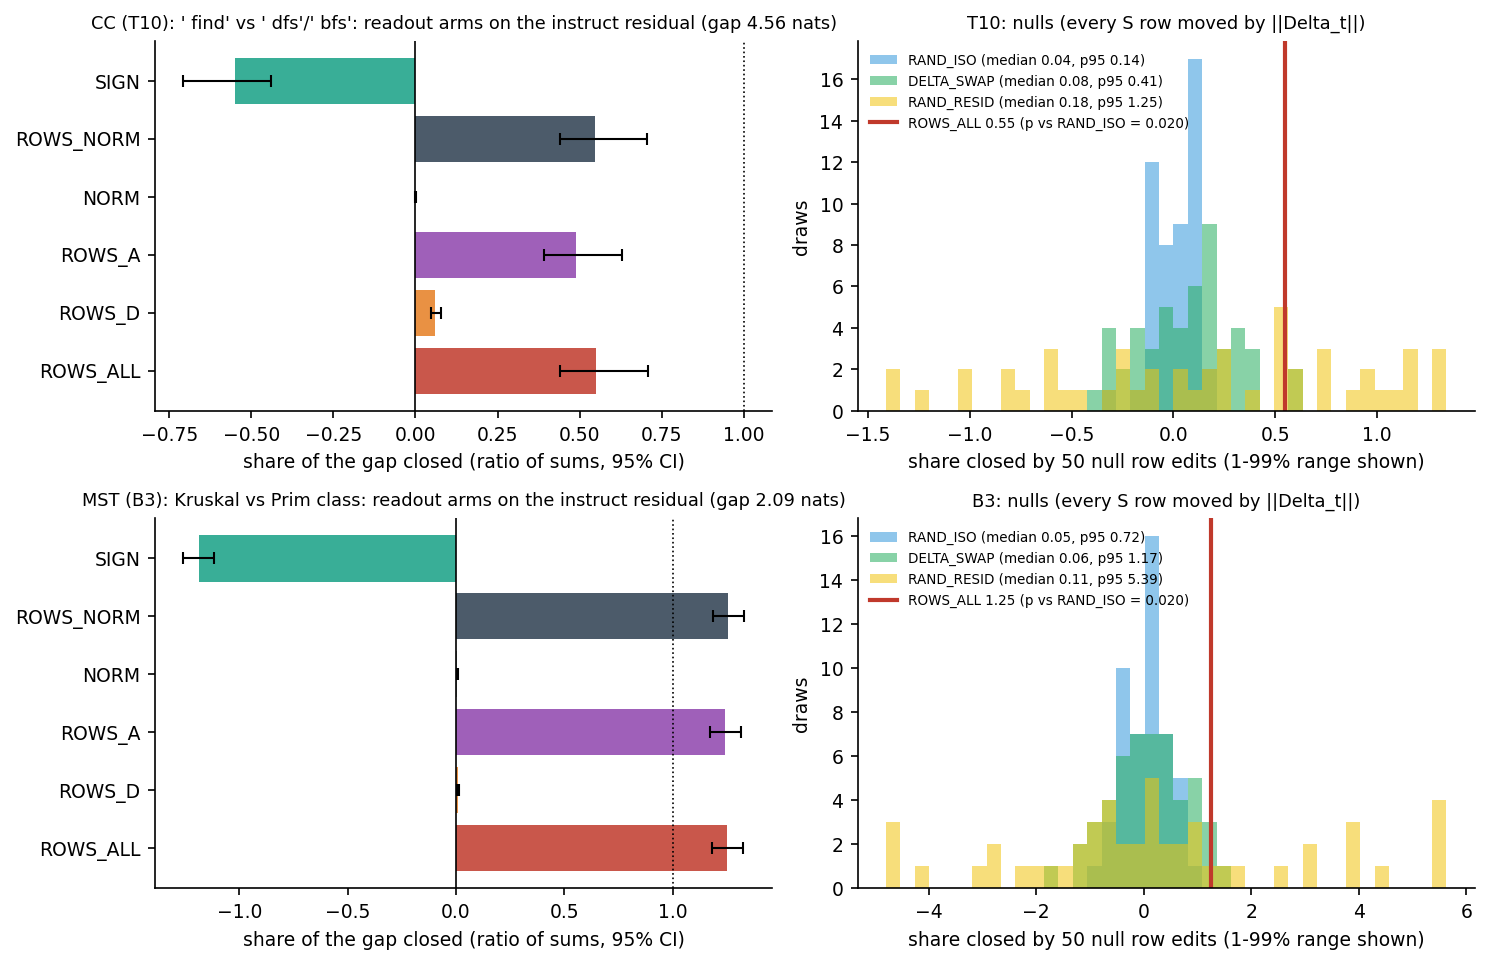

15:48:45|INFO   |saved F1_w1_shares_nulls


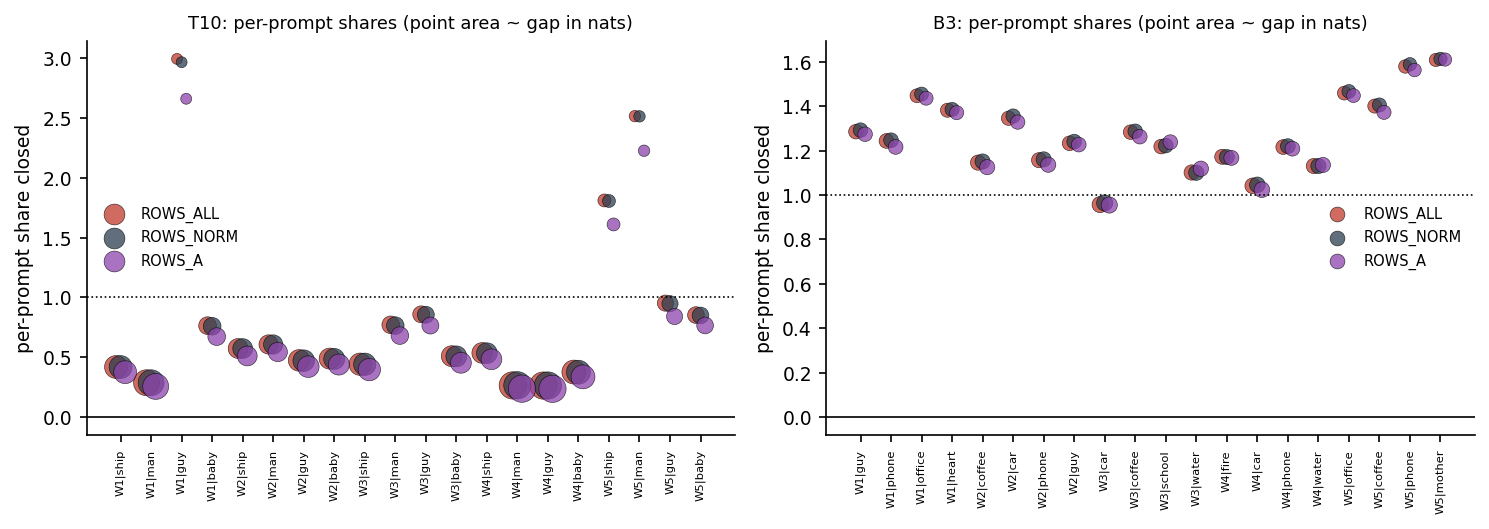

15:48:45|INFO   |saved F2_per_prompt_shares


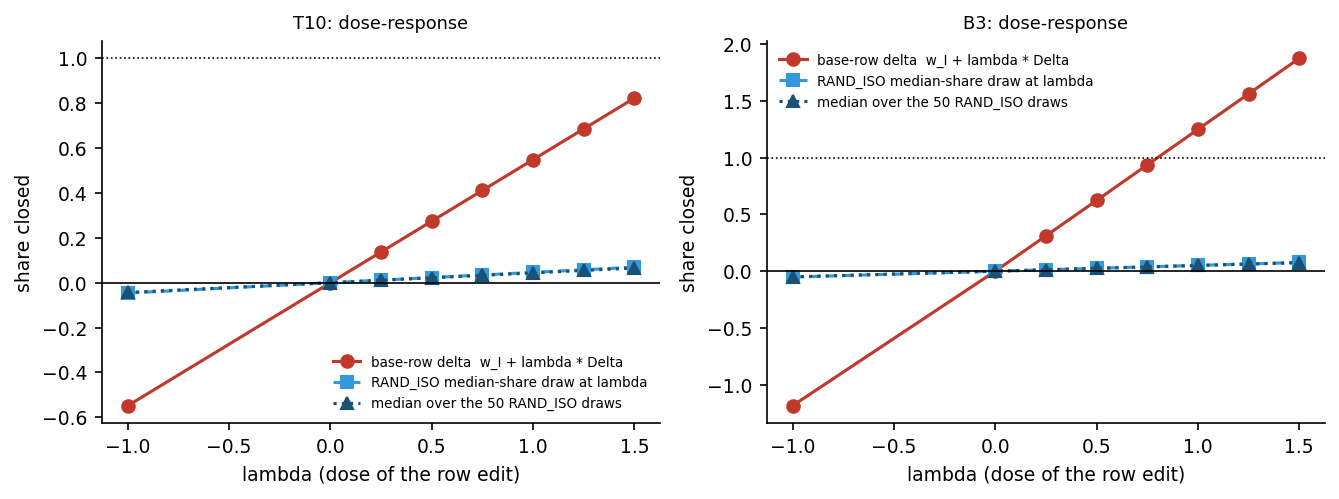

15:48:45|INFO   |saved F3_dose_response


In [18]:
f1(W1)
f2(W1)
f3(W1)

### F5 and F6: the fork states in activation space
These two figures plot actual activation coordinates, not summary statistics.

**F5 (readout plane).** It projects the 20 instruct and 20 base final-normed fork states `h_fin` onto a plane spanned by two directions:
* `u1`: the instruct readout direction, `mean w_D - mean w_A` of the instruct rows;
* `u2`: the base readout direction, orthogonalised against `u1`.

The isolines are the class margin across this plane, taken through the mean off-plane component of the states. Solid red lines use the instruct rows; dashed blue lines use the base rows, i.e. the ROWS_ALL readout. The arm moves the isolines, not the points: the instruct states stay where they are, and the readout that judges them changes.

**F6 (PCA of the block-35 outputs).** It shows the PCA of `h_pre`, the final-norm input, for both models at the fork. Arrows are the projections of the two readout directions.

`f5_f6` is the original function. Only `UnitData` is built from the data file.

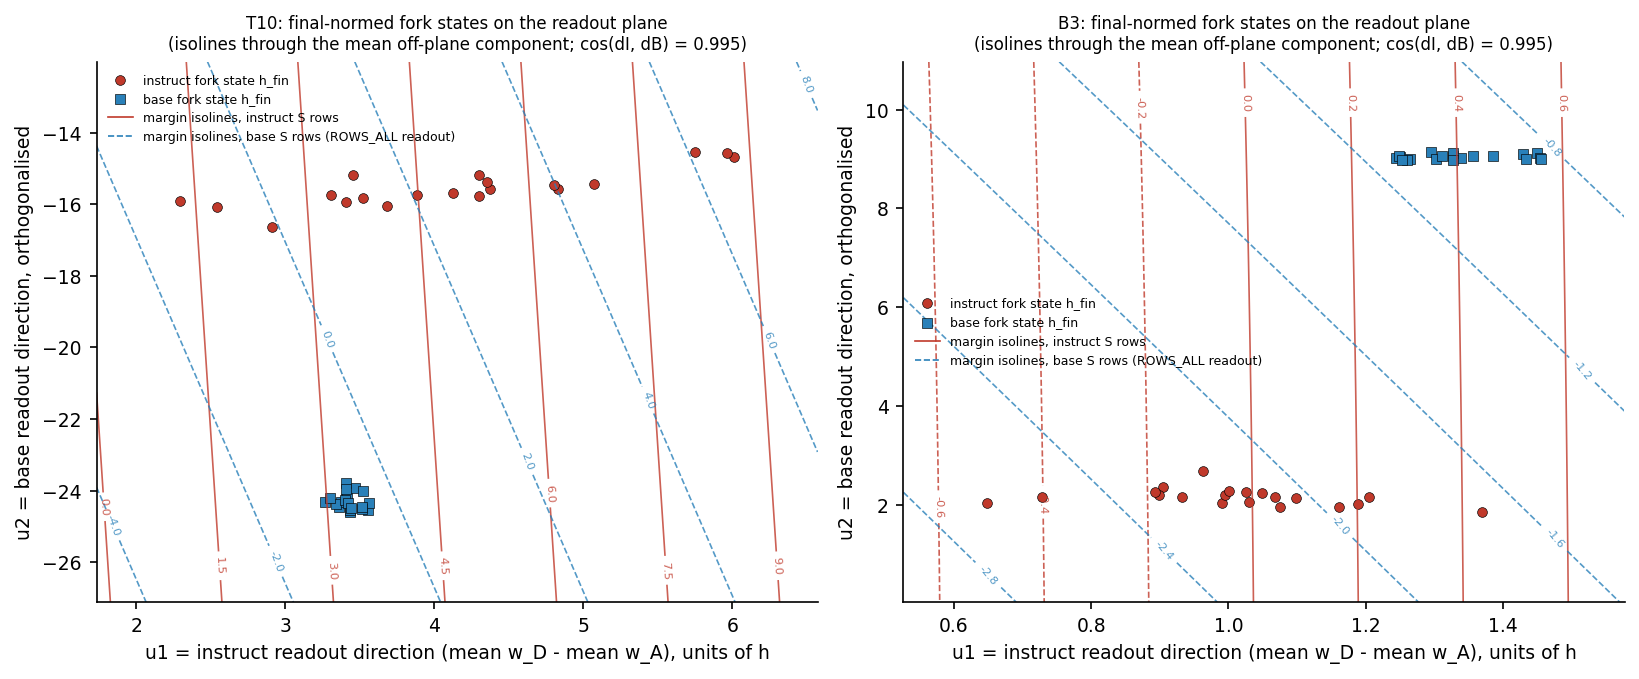

15:48:46|INFO   |saved F5_readout_plane


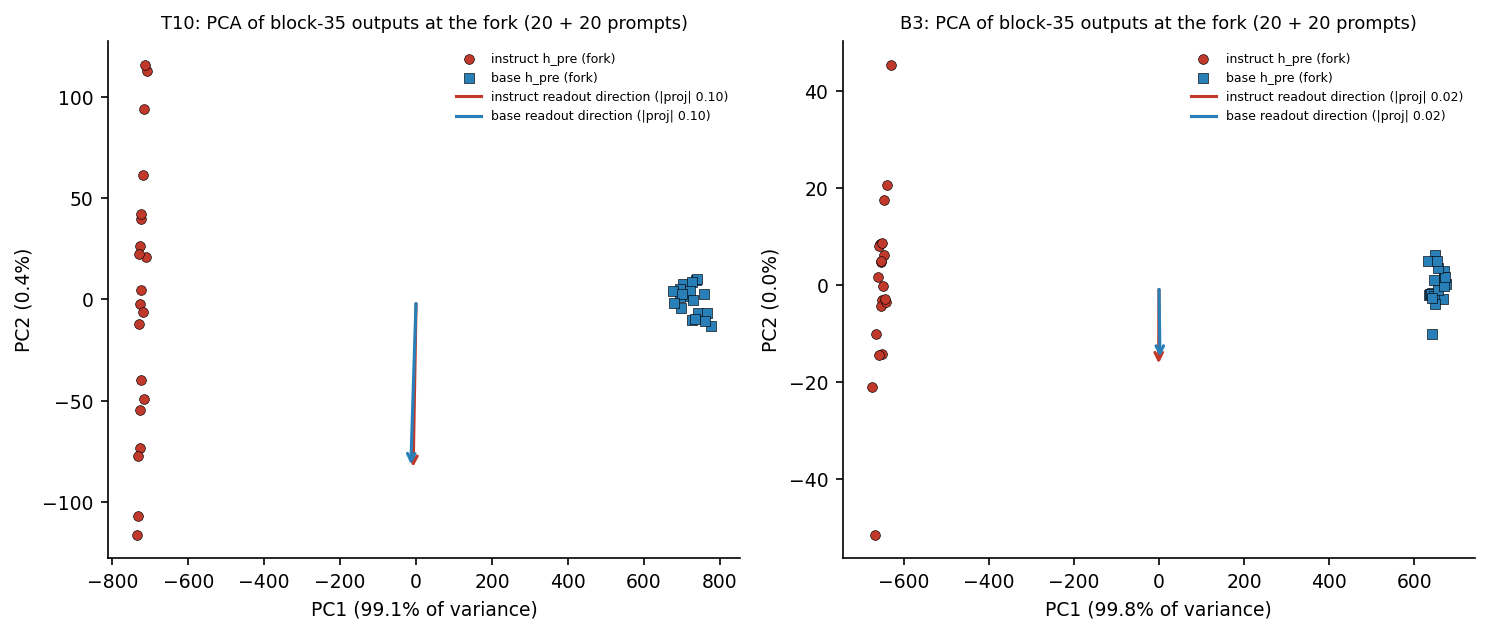

15:48:46|INFO   |saved F6_pca_block35


In [19]:
def f5_f6() -> None:
    fig5, ax5 = plt.subplots(1, 2, figsize=(11, 4.6))
    fig6, ax6 = plt.subplots(1, 2, figsize=(10, 4.3))
    for k, u in enumerate(UNITS_TF):
        d = UnitData(u, units, gI, gB)            # was: UnitData(u, units, WI, WB, gI, gB, need_logits=False)
        WI_S, WB_S = d.WI_S.double(), d.WB_S.double()
        dI = WI_S[:d.nD].mean(0) - WI_S[d.nD:].mean(0)
        dB = WB_S[:d.nD].mean(0) - WB_S[d.nD:].mean(0)
        u1 = dI / dI.norm()
        v = dB - (dB @ u1) * u1
        u2 = v / v.norm()
        H = torch.cat([d.hfI, d.hfB]).double()
        a, b = (H @ u1).numpy(), (H @ u2).numpy()
        off = H - torch.outer(H @ u1, u1) - torch.outer(H @ u2, u2)
        off_mean = off.mean(0)
        ga = np.linspace(a.min() - 0.15 * np.ptp(a), a.max() + 0.15 * np.ptp(a), 120)
        gb = np.linspace(b.min() - 0.25 * np.ptp(b), b.max() + 0.25 * np.ptp(b), 120)
        A_, B_ = np.meshgrid(ga, gb)
        G = (off_mean[None, None, :] + torch.from_numpy(A_)[..., None] * u1 + torch.from_numpy(B_)[..., None] * u2)
        G = G.reshape(-1, G.shape[-1])

        def mgrid(rows: torch.Tensor) -> np.ndarray:
            z = G @ rows.T
            return (torch.logsumexp(z[:, :d.nD], -1) - torch.logsumexp(z[:, d.nD:], -1)).numpy().reshape(A_.shape)
        MI, MB = mgrid(WI_S), mgrid(WB_S)
        ax = ax5[k]
        cs1 = ax.contour(A_, B_, MI, levels=7, colors=C["instr"], linewidths=0.8, alpha=0.8)
        ax.clabel(cs1, fontsize=5.5, fmt="%.1f")
        cs2 = ax.contour(A_, B_, MB, levels=7, colors=C["base"], linewidths=0.8, linestyles="--", alpha=0.8)
        ax.clabel(cs2, fontsize=5.5, fmt="%.1f")
        n = len(d.pids)
        ax.scatter(a[:n], b[:n], color=C["instr"], s=22, edgecolor="k", lw=0.3, label="instruct fork state h_fin")
        ax.scatter(a[n:], b[n:], color=C["base"], s=22, marker="s", edgecolor="k", lw=0.3,
                   label="base fork state h_fin")
        ax.plot([], [], color=C["instr"], lw=0.8, label="margin isolines, instruct S rows")
        ax.plot([], [], color=C["base"], lw=0.8, ls="--", label="margin isolines, base S rows (ROWS_ALL readout)")
        ax.set_xlabel("u1 = instruct readout direction (mean w_D - mean w_A), units of h")
        ax.set_ylabel("u2 = base readout direction, orthogonalised")
        ax.set_title(f"{u}: final-normed fork states on the readout plane\n(isolines through the mean off-plane "
                     f"component; cos(dI, dB) = {float(dI @ dB / dI.norm() / dB.norm()):.3f})", fontsize=8)
        ax.legend(fontsize=6, frameon=False, loc="best")
        # F6 PCA of block-35 outputs (final-norm inputs) at the fork
        P = torch.cat([d.hpI.float(), d.hpB.float()]).double()
        mu = P.mean(0)
        Uu, Ss, Vt = torch.linalg.svd(P - mu, full_matrices=False)
        pcs = Vt[:2]
        Y = ((P - mu) @ pcs.T).numpy()
        ev = (Ss ** 2 / (Ss ** 2).sum()).numpy()
        ax = ax6[k]
        ax.scatter(Y[:n, 0], Y[:n, 1], color=C["instr"], s=22, edgecolor="k", lw=0.3, label="instruct h_pre (fork)")
        ax.scatter(Y[n:, 0], Y[n:, 1], color=C["base"], s=22, marker="s", edgecolor="k", lw=0.3,
                   label="base h_pre (fork)")
        sc = 0.35 * np.abs(Y).max()
        for vec, col, lab in ((dI, C["instr"], "instruct readout direction"), (dB, C["base"], "base readout direction")):
            p2 = (pcs @ (vec / vec.norm())).numpy()
            ax.annotate("", xy=(sc * p2[0] / max(1e-9, np.linalg.norm(p2)) * min(1, 3 * np.linalg.norm(p2)),
                                sc * p2[1] / max(1e-9, np.linalg.norm(p2)) * min(1, 3 * np.linalg.norm(p2))),
                        xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=col, lw=1.5))
            ax.plot([], [], color=col, label=f"{lab} (|proj| {np.linalg.norm(p2):.2f})")
        ax.set_xlabel(f"PC1 ({100 * ev[0]:.1f}% of variance)")
        ax.set_ylabel(f"PC2 ({100 * ev[1]:.1f}%)")
        ax.set_title(f"{u}: PCA of block-35 outputs at the fork (20 + 20 prompts)", fontsize=8.5)
        ax.legend(fontsize=6, frameon=False)
    fig5.tight_layout()
    save(fig5, "F5_readout_plane")
    save(fig6, "F6_pca_block35")


f5_f6()

## What the GPU stages found (reported by the artifact, not re-run here)
**W1 generation (`w1gen`, `ext`).** Programs were generated with 30 common-random-number slots per arm. The only difference between arms is the readout at the fork step. Correct means a DFS program for T10, or a Prim program for B3, that passes the hidden tests.

| arm at the fork | T10 correct DFS / 30 | B3 correct Prim / 30 |
|---|---|---|
| TWIN (unchanged instruct readout) | 1 | 0 |
| **ROWS** (base fork-class rows, λ = 1) | **5** (vs TWIN 4:0, p = 0.125) | **24** (24:0, p = 1.2e-7) |
| RAND_MED (median isotropic draw) | 1 | 0 |
| FPD (base fork logits) | 15 | 17 |
| ROWS ×2 / ×3 (`w_I + 2·Delta`, `w_I + 3·Delta`) | **21 / 30** | 27 / 27 |
| RAND_MED ×3 / RAND_RESID max-draw ×3 / DELTA_SWAP max-draw ×3 | 1 / 30 / 30 | 3 / 27 / 27 |

Notes on the table:
* **Committed verdict for T10: NOT SUPPORTED.** ROWS reached 5/30, below the registered bar of 10/30.
* **Power extension.** Pooled over 90 CRN pairs, ROWS gives 21/90 correct DFS against 4/90 for TWIN (17:0, p = 1.5e-5).
* **Correctness.** Every program in the dose arms passes the hidden tests.
* **Novelty.** No edit produced a correct program outside the known classes.

**W2 (late MLPs 26-35 swapped to base).** The share is -0.145, against 0.461 for Hungarian-matched early swaps, so the committed rule fails. Same-layer random deltas move the margin by comparable amounts. **W3 (Gemma-3-4b).** The base rows *widen* the gap (share -0.253), so the effect depends on the model family.

**Answer to "can we make the model pick a less default solution?"**

At the decision token, post-training stored much of Qwen's default in the **readout**: it suppressed the alternatives' unembedding rows (`' dfs'` and `' bfs'`) more than it promoted `' find'`. Pushing those 3 of 151,936 rows along the post-training delta is a cheap lever over **which known algorithm** gets written. It is not unique, though. The best random row edit of the same norm that points into the residual subspace does as well, which is the "readout-level, not token-specific" verdict above. It also creates no novelty.

The last cell puts this notebook's numbers next to the reported ones.


=== T10: connected components  |  gap 4.558 nats (reported 4.558)
arm             share            95% CI  reported   |diff|
ROWS_ALL       0.5485    [0.440, 0.707]    0.5485  0.0e+00
ROWS_D         0.0595    [0.047, 0.078]    0.0595  0.0e+00
ROWS_A         0.4889    [0.392, 0.629]    0.4889  0.0e+00
NORM          -0.0003   [-0.001, 0.000]   -0.0003  0.0e+00
ROWS_NORM      0.5468    [0.439, 0.704]    0.5468  0.0e+00
FULL_UNEMB     0.5485    [0.440, 0.707]    0.5485  0.0e+00
SIGN          -0.5483  [-0.707, -0.440]   -0.5483  0.0e+00
DOSE_0.5       0.2742    [0.220, 0.353]    0.2742  0.0e+00
DOSE_1.5       0.8228    [0.660, 1.060]    0.8228  0.0e+00
null           median      p95      max  p(ROWS_ALL)   reported median / p95 / max / p
RAND_ISO        0.044    0.138    0.210       0.0196   0.044 / 0.138 / 0.210 / 0.0196
DELTA_SWAP      0.085    0.405    0.625       0.0588   0.085 / 0.405 / 0.625 / 0.0588
RAND_RESID      0.181    1.252    2.328       0.3725   0.181 / 1.252 / 2.328 / 0.372

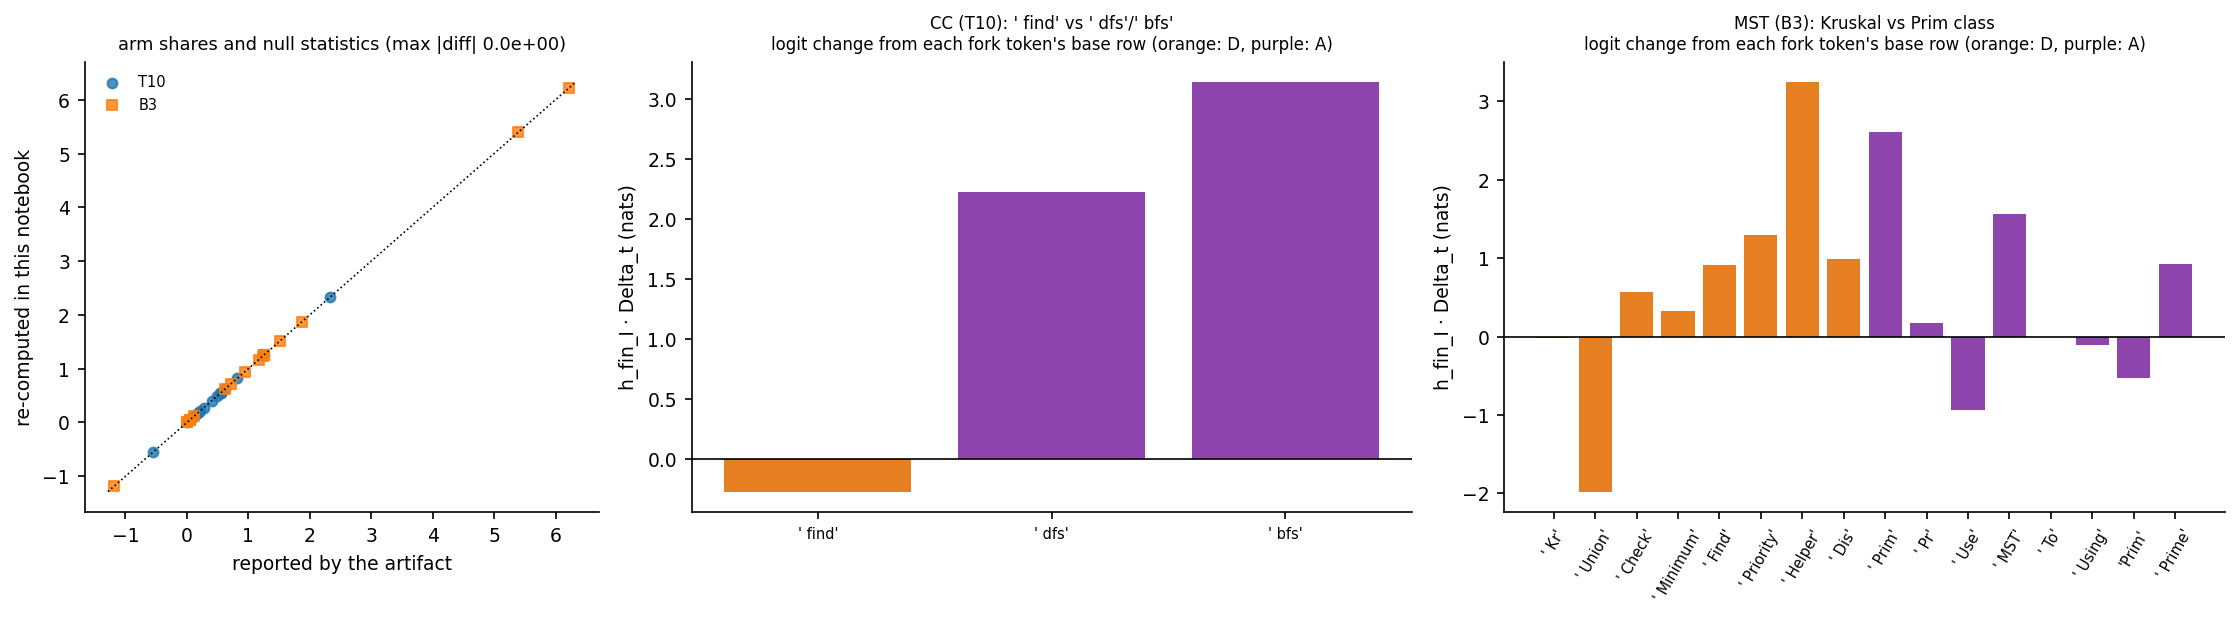

In [20]:
# Key numbers: this notebook's re-computation next to the artifact's reported values (results/w1_tf_summary.json)
pairs = []
for u in UNITS_TF:
    U, R = W1["units"][u], units[u]["reported"]
    print(f"\n=== {u}: {units[u]['name']}  |  gap {U['gap_mean']:.3f} nats (reported {R['gap_mean']:.3f})")
    print(f"{'arm':<12}{'share':>9}{'95% CI':>18}{'reported':>10}{'|diff|':>9}")
    for a in ("ROWS_ALL", "ROWS_D", "ROWS_A", "NORM", "ROWS_NORM", "FULL_UNEMB", "SIGN", "DOSE_0.5", "DOSE_1.5"):
        s, r, ci = U["arms"][a]["share"], R["arms"][a]["share"], U["arms"][a]["ci95"]
        print(f"{a:<12}{s:>9.4f}{f'[{ci[0]:.3f}, {ci[1]:.3f}]':>18}{r:>10.4f}{abs(s - r):>9.1e}")
        pairs.append((u, a, r, s))
    print(f"{'null':<12}{'median':>9}{'p95':>9}{'max':>9}{'p(ROWS_ALL)':>13}   reported median / p95 / max / p")
    for nt in NULL_TYPES:
        n_, r_ = U["nulls"][nt], R["nulls"][nt]
        tag = "" if n_["recomputed"] else "  (committed shares)"
        print(f"{nt:<12}{n_['median']:>9.3f}{n_['p95']:>9.3f}{n_['max']:>9.3f}{n_['empirical_p_rows_all']:>13.4f}   "
              f"{r_['median']:.3f} / {r_['p95']:.3f} / {r_['max']:.3f} / {r_['empirical_p_rows_all']:.4f}{tag}")
        pairs += [(u, f"{nt} {k}", r_[k], n_[k]) for k in ("median", "p95", "max")]
    F, RF = U["factorial_2x2"], R["factorial_2x2"]
    print(f"2x2 interaction {F['interaction_mean']:+.3f} nats (reported {RF['interaction_mean']:+.3f}); "
          f"unembedding-only share on the base residual {F['share_unembedding_only_on_base_resid']:.3f} "
          f"(reported {RF['share_unembedding_only_on_base_resid']:.3f})")
    print(f"verdict: {U['verdict']} / {U['specificity_qualifier']}   (reported: {R['verdict']} / "
          f"{R['specificity_qualifier']}; role {U['verdict_role']})")

fig, axes = plt.subplots(1, 1 + len(UNITS_TF), figsize=(5 + 5 * len(UNITS_TF), 4.2),
                         gridspec_kw={"width_ratios": [1] + [1.4] * len(UNITS_TF)})
ax = axes[0]
rep_v, nb_v = np.array([p[2] for p in pairs]), np.array([p[3] for p in pairs])
for u, mk in zip(UNITS_TF, ("o", "s")):
    ix = [i for i, p in enumerate(pairs) if p[0] == u]
    ax.scatter(rep_v[ix], nb_v[ix], marker=mk, s=22, alpha=0.8, label=u)
lim = [min(rep_v.min(), nb_v.min()) - 0.1, max(rep_v.max(), nb_v.max()) + 0.1]
ax.plot(lim, lim, "k:", lw=0.8)
ax.set_xlabel("reported by the artifact")
ax.set_ylabel("re-computed in this notebook")
ax.set_title(f"arm shares and null statistics (max |diff| {np.abs(rep_v - nb_v).max():.1e})", fontsize=8.5)
ax.legend(fontsize=7, frameon=False)
for ax, u in zip(axes[1:], UNITS_TF):
    U = W1["units"][u]
    toks = list(U["per_token_logit_change"])
    vals = [U["per_token_logit_change"][t]["mean"] for t in toks]
    cols = [C["ROWS_D"] if U["per_token_logit_change"][t]["class"] == "D" else C["ROWS_A"] for t in toks]
    ax.bar(range(len(toks)), vals, color=cols)
    ax.set_xticks(range(len(toks)), [repr(t) for t in toks], rotation=60 if len(toks) > 4 else 0, fontsize=7)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_ylabel("h_fin_I · Delta_t (nats)")
    ax.set_title(f"{NAMES[u]}\nlogit change from each fork token's base row (orange: D, purple: A)", fontsize=8)
fig.tight_layout()
plt.show()